In [1]:
from preprocessing import data_loaders
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from funcs import *

plt.style.use('seaborn-v0_8-paper')
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["savefig.format"] = 'png'

In [2]:
data = data_loaders()
train_df, val_df, test_df = [ds.df for ds in data['datasets']]

In [3]:
names = ['train', 'test', 'val']
for name, df in zip(names, [train_df, val_df, test_df]):
    df['split'] = name
df = pd.concat([train_df, val_df, test_df]).drop('path', axis=1)
classes = list(df['class_name'].unique())

### Dataset split and class distribution 

In [46]:
print(df.groupby('split').sum()['label'].to_markdown())
print("\n", df.groupby(['split','class_name']).count())

| split   |   label |
|:--------|--------:|
| test    |    4200 |
| train   |   19600 |
| val     |    4200 |

                               label
split class_name                   
test  dyed-lifted-polyps        150
      dyed-resection-margins    150
      esophagitis               150
      normal-cecum              150
      normal-pylorus            150
      normal-z-line             150
      polyps                    150
      ulcerative-colitis        150
train dyed-lifted-polyps        700
      dyed-resection-margins    700
      esophagitis               700
      normal-cecum              700
      normal-pylorus            700
      normal-z-line             700
      polyps                    700
      ulcerative-colitis        700
val   dyed-lifted-polyps        150
      dyed-resection-margins    150
      esophagitis               150
      normal-cecum              150
      normal-pylorus            150
      normal-z-line             150
      polyps            

In [47]:
print(classes)

['esophagitis', 'ulcerative-colitis', 'dyed-lifted-polyps', 'normal-pylorus', 'normal-cecum', 'normal-z-line', 'polyps', 'dyed-resection-margins']


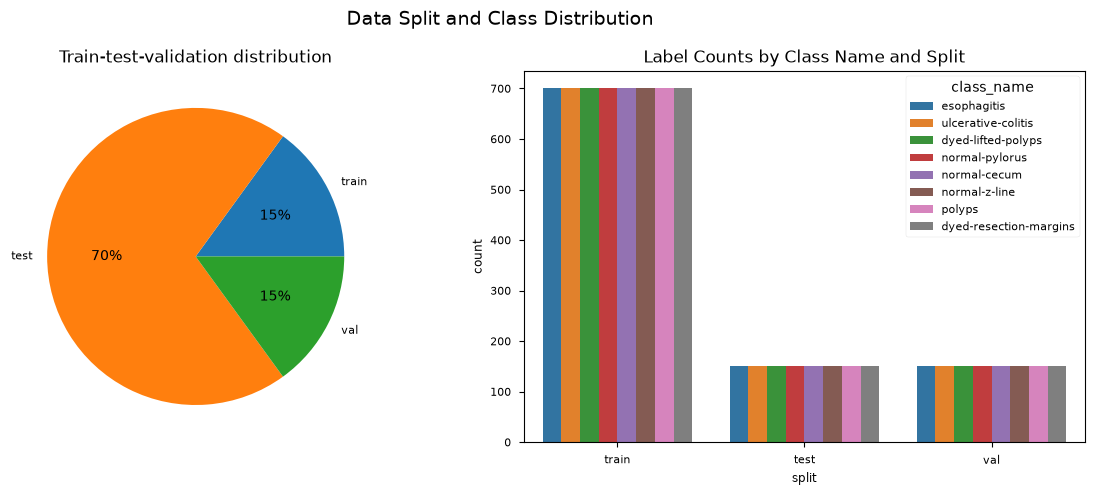

In [48]:
fig, axs = plt.subplots(1, 2, figsize=(12,5))
fig.suptitle('Data Split and Class Distribution', fontsize=14)

data = df.groupby('split').sum()
axs[0].pie(data['label'], labels=names, autopct='%.0f%%')
axs[0].set_title('Train-test-validation distribution', fontsize=12)
axs[1] = sns.countplot(data=df, x='split', hue='class_name')
axs[1].set_title('Label Counts by Class Name and Split', fontsize=12)

plt.tight_layout()
plt.savefig("DataSplit_ClassDistribution.png")
plt.show()

### Model architectures and parameter counts

In [ ]:
MODEL_CHECKPOINTS = {
    "small_cnn": CHECKPOINT_DIR / "small_cnn_best.pth",
    "resnet18": CHECKPOINT_DIR / "resnet18_best.pth",
    "vit_b_16": CHECKPOINT_DIR / "vit_b_16_best.pth",
    "efficientnet_b0": CHECKPOINT_DIR / "efficientnet_b0_best.pth",
    "alexnet": CHECKPOINT_DIR / "alexnet_best.pth",
    "efficientnet_b0_scratch": CHECKPOINT_DIR / "efficientnet_b0_scratch_best.pth",
    "efficientnet_b0_finetuned": CHECKPOINT_DIR / "efficientnet_b0_finetuned_best.pth",
}

In [5]:
from models import build_model
from torchinfo import summary
from torchviz import make_dot

x = torch.randn(16, 3, 224, 224)

for key, path in MODEL_CHECKPOINTS.items():
    model = build_model(key)  # Replace with your custom class, e.g., MyModel()
    # 2. Load the state dictionary
    checkpoint = torch.load(path, map_location=DEVICE, weights_only=False)
    state_dict = checkpoint.get("model_state_dict", checkpoint.get("state_dict"))
    model.load_state_dict(state_dict, strict=True)
    model.eval()
    
    print(f"Model {key}")
    print(summary(model, input_size=(16, 3, 224, 224)), "\n")   

Model small_cnn
Layer (type:depth-idx)                   Output Shape              Param #
SmallCNN                                 [16, 8]                   --
├─Sequential: 1-1                        [16, 256, 14, 14]         --
│    └─Sequential: 2-1                   [16, 32, 112, 112]        --
│    │    └─Conv2d: 3-1                  [16, 32, 224, 224]        864
│    │    └─BatchNorm2d: 3-2             [16, 32, 224, 224]        64
│    │    └─ReLU: 3-3                    [16, 32, 224, 224]        --
│    │    └─MaxPool2d: 3-4               [16, 32, 112, 112]        --
│    └─Sequential: 2-2                   [16, 64, 56, 56]          --
│    │    └─Conv2d: 3-5                  [16, 64, 112, 112]        18,432
│    │    └─BatchNorm2d: 3-6             [16, 64, 112, 112]        128
│    │    └─ReLU: 3-7                    [16, 64, 112, 112]        --
│    │    └─MaxPool2d: 3-8               [16, 64, 56, 56]          --
│    └─Sequential: 2-3                   [16, 128, 28, 28]     

### Overall test metrics

### Train results

| model                     | test_samples | accuracy | macro_f1 | macro_specificity | mcc      | inference_seconds | ms_per_image | checkpoint_epoch | validation_macro_f1 |
| ------------------------- | ------------ | -------- | -------- | ----------------- | -------- | ----------------- | ------------ | ---------------- | ------------------- |
| efficientnet_b0_finetuned | 1,200        | 0.9225   | 0.922499 | 0.988929          | 0.911444 | 22.32027          | 18.60022     | 25               | 0.914842            |
| vit_b_16                  | 1,200        | 0.901667 | 0.901615 | 0.985952          | 0.887702 | 30.52189          | 25.43491     | 7                | 0.902163            |
| efficientnet_b0           | 1,200        | 0.888333 | 0.888015 | 0.984048          | 0.872722 | 18.33849          | 15.28207     | 9                | 0.890066            |
| efficientnet_b0_scratch   | 1,200        | 0.8725   | 0.872261 | 0.981786          | 0.854328 | 21.13467          | 17.61223     | 38               | 0.883605            |
| small_cnn                 | 1,200        | 0.860833 | 0.860174 | 0.980119          | 0.841718 | 21.66639          | 18.05533     | 33               | 0.839722            |
| resnet18                  | 1,200        | 0.86     | 0.85979  | 0.98              | 0.840592 | 23.42216          | 19.51846     | 10               | 0.868076            |
| alexnet                   | 1,200        | 0.8225   | 0.821075 | 0.974643          | 0.797675 | 19.90978          | 16.59148     | 8                | 0.804682            |

### Training curves

In [6]:
dfs = []
for key in MODEL_CHECKPOINTS.keys():
    dfs.append(pd.read_csv(RESULT_DIR / f"train_results/{key}_history.csv"))
df = pd.concat(dfs)
aux = {"efficientnet_b8_finetuned":"efficientnet_b0_finetuned"}
df = df.replace({'model':aux})
df_10 = df[df['epoch']<=10]
df_m = df[(df['model']=='small_cnn')|(df['model']=='efficientnet_b0_scratch')|(df['model']=='efficientnet_b0_finetuned')]

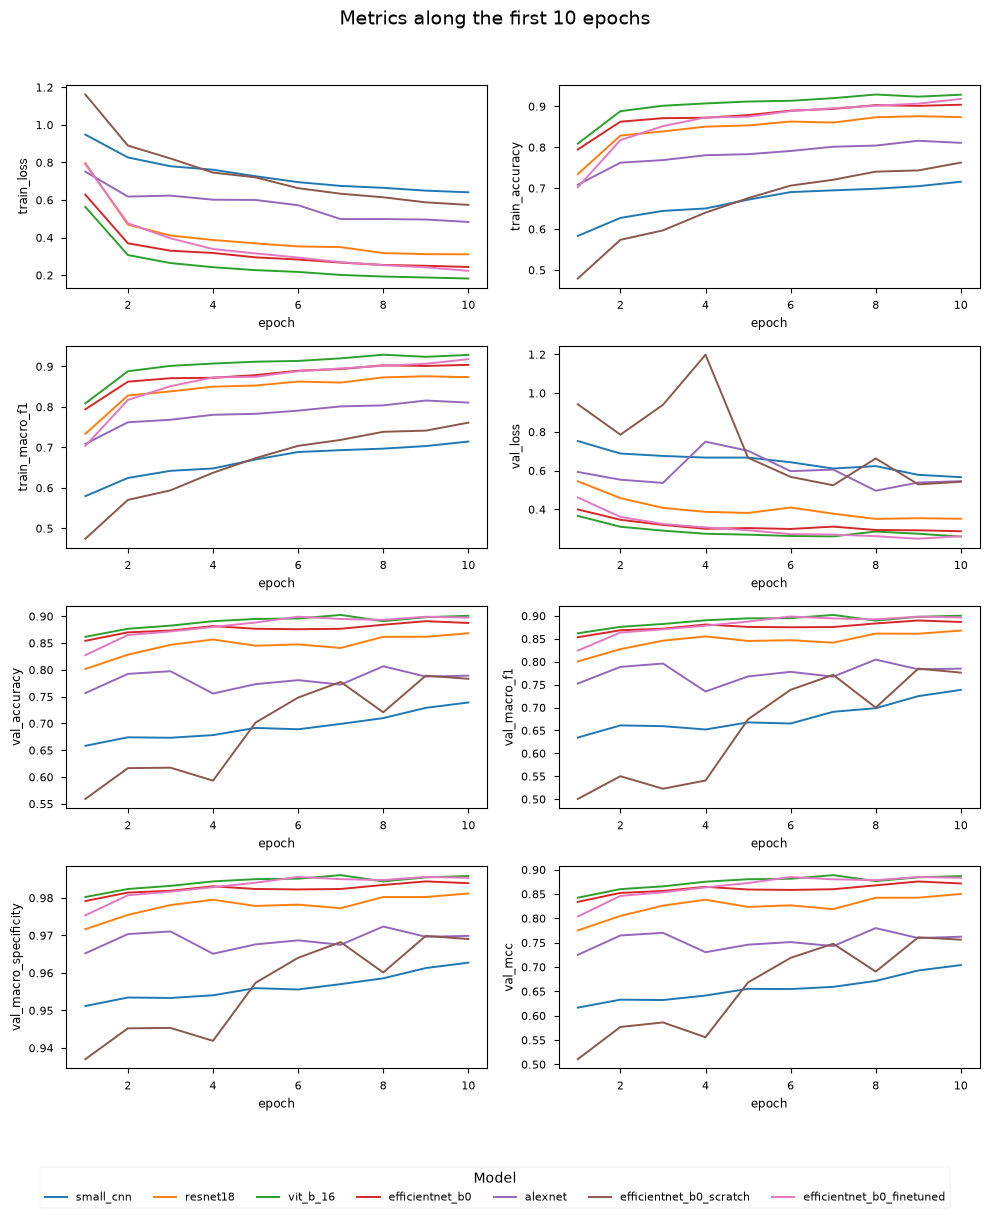

In [21]:
fig, axs = plt.subplots(4, 2, figsize=(10, 12))
axs = axs.flatten()
cols = df.columns[2:]

for i in range(len(cols)):
    sns.lineplot(data=df_10, x='epoch', y=cols[i], hue='model', ax=axs[i])

unique_models = df_10['model'].unique()
handles = axs[0].get_lines()[:len(unique_models)]

for ax in axs:
    if ax.get_legend() is not None:
        ax.get_legend().remove()

plt.suptitle("Metrics along the first 10 epochs", fontsize=14)
fig.legend(handles, unique_models, title='Model', loc='upper center', bbox_to_anchor=(0.5, 0.02), ncol=len(unique_models))

plt.tight_layout(rect=[0, 0.05, 1, 0.96])
plt.savefig("Metrics_vs_epochs.png", bbox_inches='tight', dpi=300)
plt.show()

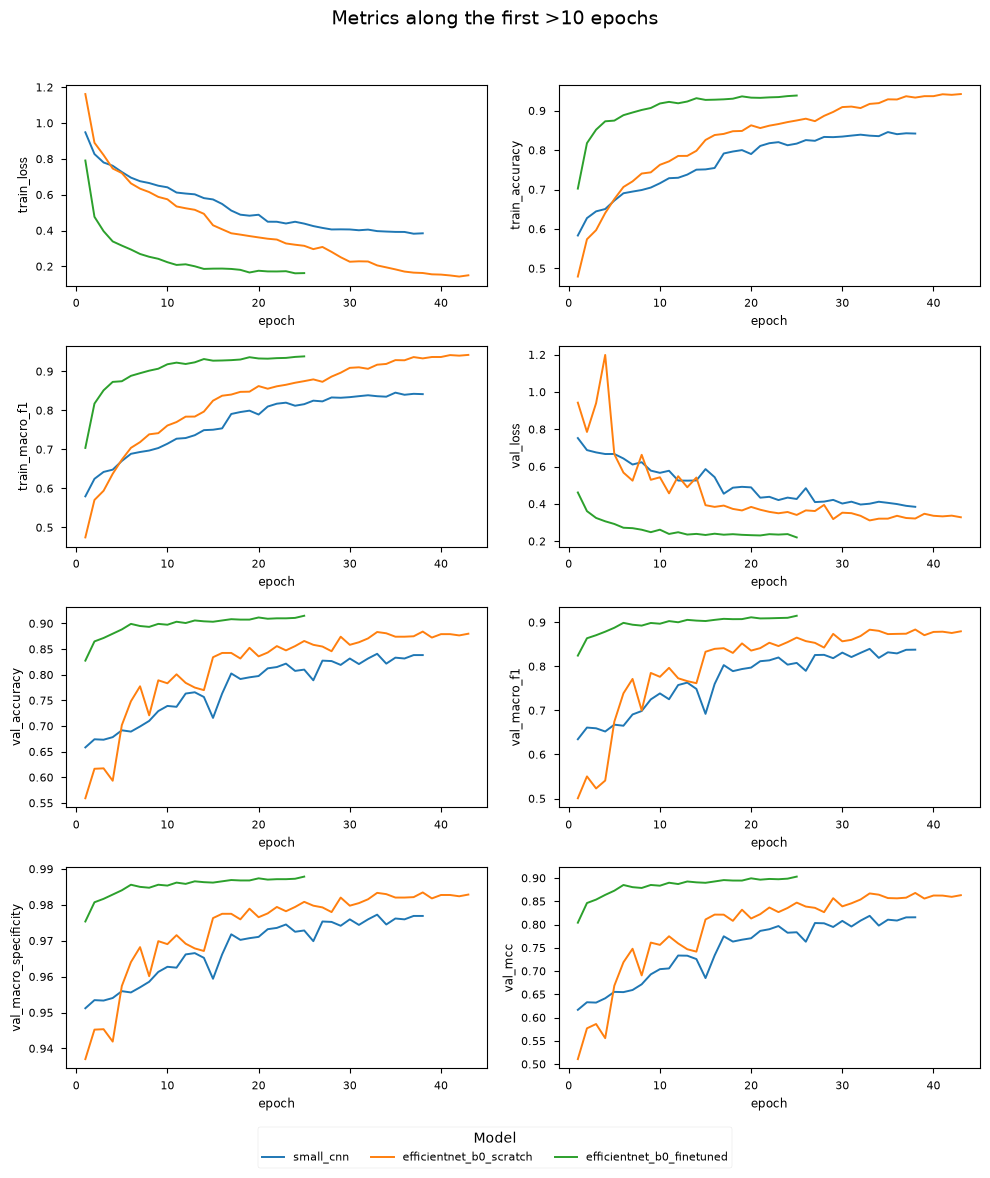

In [22]:
fig, axs = plt.subplots(4, 2, figsize=(10, 12))
axs = axs.flatten()
cols = df.columns[2:]

for i in range(len(cols)):
    sns.lineplot(data=df_m, x='epoch', y=cols[i], hue='model', ax=axs[i])
handles, labels = axs[0].get_legend().get_lines(), [t.get_text() for t in axs[0].get_legend().get_texts()]

for ax in axs:
    if ax.get_legend() is not None:
        ax.get_legend().remove()

plt.suptitle("Metrics along the first >10 epochs", fontsize=14)
plt.tight_layout(rect=[0, 0.05, 1, 0.96])
fig.legend(handles, labels, title='Model', loc='lower center', bbox_to_anchor=(0.5, 0.01), ncol=len(labels))
plt.savefig("Metrics_vs_Longer_Epochs.png", bbox_inches='tight', dpi=300)
plt.show()

### Confussion matrices

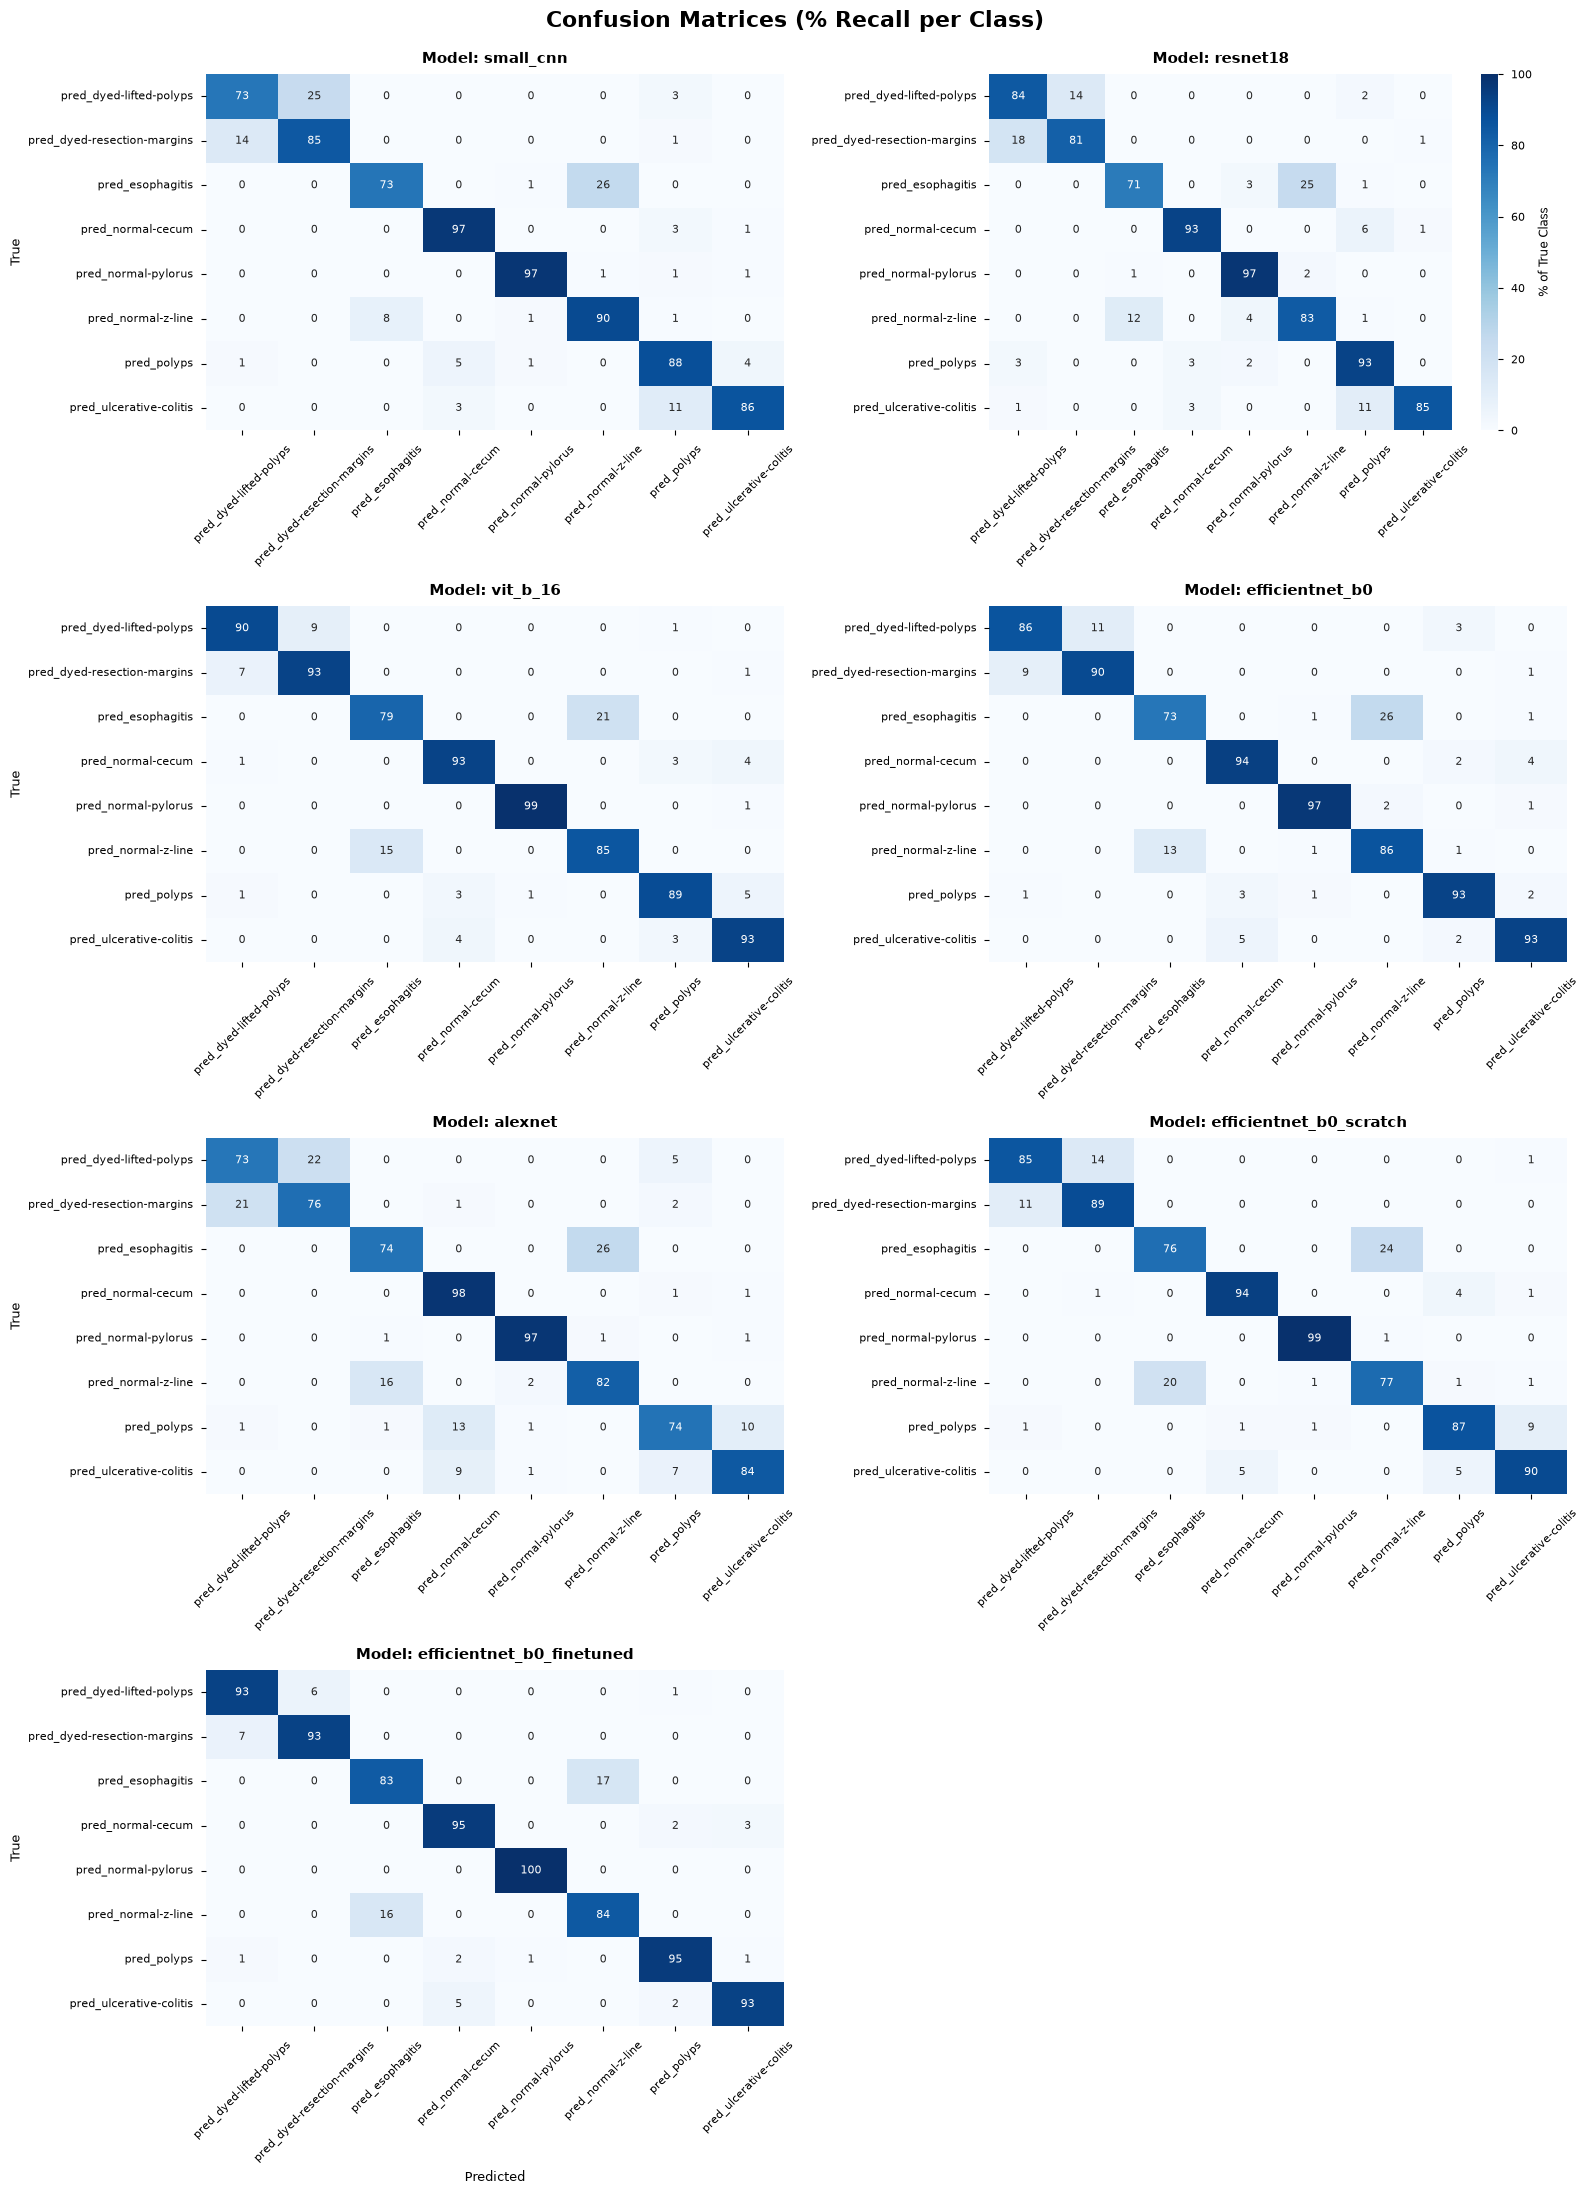

In [ ]:
fig, axs = plt.subplots(4, 2, figsize=(16, 22))
axs = axs.flatten()
class_names = ['pred_dyed-lifted-polyps', 'pred_dyed-resection-margins', 'pred_esophagitis', 'pred_normal-cecum', 'pred_normal-pylorus',
       'pred_normal-z-line', 'pred_polyps', 'pred_ulcerative-colitis']

vmin, vmax = 0, 100
for i, (key, checkpoint_path) in enumerate(MODEL_CHECKPOINTS.items()):
    csv_file = OUTPUT_DIR / f"{key}_confusion_matrix.csv"
    cf_matrix = pd.read_csv(csv_file).rename(columns={'Unnamed: 0': 'class'}).set_index('class')
    matrix_vals = cf_matrix.values.astype('float')
    row_sums = matrix_vals.sum(axis=1, keepdims=True)
    norm_matrix = np.divide(matrix_vals, row_sums, out=np.zeros_like(matrix_vals), where=row_sums!=0) * 100
    sns.heatmap(
        norm_matrix, 
        annot=True, 
        fmt='.0f', 
        cmap='Blues', 
        ax=axs[i],
        cbar=(i == 1), # Draw colorbar only once on the top-right plot
        cbar_kws={'label': '% of True Class'} if i == 1 else None,
        vmin=vmin, 
        vmax=vmax,
        xticklabels=class_names,
        yticklabels=class_names,
        annot_kws={"size": 8}
    )
    axs[i].set_title(f"Model: {key}", fontsize=11, fontweight='bold', pad=8)
    axs[i].tick_params(axis='x', rotation=45, labelsize=8)
    axs[i].tick_params(axis='y', rotation=0, labelsize=8)
    axs[i].set_xlabel('Predicted' if i >= 6 else '', fontsize=9)
    axs[i].set_ylabel('True' if i % 2 == 0 else '', fontsize=9)
    
for j in range(len(MODEL_CHECKPOINTS), len(axs)):
    fig.delaxes(axs[j])

plt.suptitle("Confusion Matrices (% Recall per Class)", fontsize=16, y=0.995, fontweight='bold')
plt.tight_layout()
plt.savefig("Models_Confusion_Matrices.png", bbox_inches='tight', dpi=300)
plt.show()

### Per-class metrics

In [ ]:
dfs = []
for key in MODEL_CHECKPOINTS.keys():
    df = pd.read_csv(OUTPUT_DIR / f"{key}_classification_report.csv").rename(columns={'Unnamed: 0': 'class'})
    df['model'] = key
    dfs.append(df)
df = pd.concat(dfs)
aux = {"efficientnet_b8_finetuned":"efficientnet_b0_finetuned"}
df = df.replace({'model':aux})

,class,precision,recall,f1-score,support,model
0,dyed-lifted-polyps,0.825758,0.726667,0.773050,150.0000,small_cnn
1,dyed-resection-margins,0.774390,0.846667,0.808917,150.0000,small_cnn
2,esophagitis,0.901639,0.733333,0.808824,150.0000,small_cnn
3,normal-cecum,0.923567,0.966667,0.944625,150.0000,small_cnn
4,normal-pylorus,0.966887,0.973333,0.970100,150.0000,small_cnn
...,...,...,...,...,...,...
6,polyps,0.953333,0.953333,0.953333,150.0000,efficientnet_b0_finetuned
7,ulcerative-colitis,0.965517,0.933333,0.949153,150.0000,efficientnet_b0_finetuned
8,accuracy,0.922500,0.922500,0.922500,0.9225,efficientnet_b0_finetuned
9,macro avg,0.922610,0.922500,0.922499,1200.0000,efficientnet_b0_finetuned


In [114]:
for meassure in df.columns[1:-1]:
    print(meassure)
    aux = df[['class', 'model', meassure]]
    n_df = {}
    for model in MODEL_CHECKPOINTS.keys():
        n_df[model] = aux[aux['model']==model][meassure]
        n_df['class'] = aux[aux['model']==model]['class']
    m_df = pd.DataFrame(data = n_df).set_index('class')
    print(m_df.to_markdown(), "\n")

precision
| class                  |   small_cnn |   resnet18 |   vit_b_16 |   efficientnet_b0 |   alexnet |   efficientnet_b0_scratch |   efficientnet_b0_finetuned |
|:-----------------------|------------:|-----------:|-----------:|------------------:|----------:|--------------------------:|----------------------------:|
| dyed-lifted-polyps     |    0.825758 |   0.792453 |   0.912162 |          0.895833 |  0.767606 |                  0.876712 |                    0.921053 |
| dyed-resection-margins |    0.77439  |   0.853147 |   0.908497 |          0.89404  |  0.77551  |                  0.858974 |                    0.939597 |
| esophagitis            |    0.901639 |   0.849206 |   0.843972 |          0.851562 |  0.804348 |                  0.791667 |                    0.838926 |
| normal-cecum           |    0.923567 |   0.945578 |   0.926667 |          0.915584 |  0.812155 |                  0.94     |                    0.934641 |
| normal-pylorus         |    0.966887 |   0.918